# Anomalie detectie
In veel processen is het niet zozeer belangrijk om het gemiddelde van iets te kunnen voorspellen, dan wel om uitschieters te zien en te kunnen ingrijpen. Denk aan industriële processen, waarbij uitschieters in een productieproces vaak wijzen op een productiefout, en dus op een product dat uit het systeem moet worden gehaald.

Ook systeemmonitoring, het bekijken van datastromen vol met logs, is typisch een plaats waar je op zoek bent naar de speciale gevallen om verder te (laten) bekijken, want het gemiddelde is iets dat in dat geval een normale situatie is.

Soms is data ook om allerlei redenen *vervuild*. We bespreken dan soms van een *gecontamineerde dataset*, als dit een gekend gegeven is (bijvoorbeeld als we weten dat een machine soms bepaalde vreemde dingen doet).

Ook fraudedetectie is een domein waar actief aan anomalie detectie wordt gedaan. Zonder dit soort systemen zou het voor banken onmogelijk zijn om frauduleuze transacties op te sporen en criminele activiteiten tegen te gaan. Het is zelfs mogelijk om belastingaangiftes te controleren op de mate waarin cijfers zijn verzonnen (met de wet van Benford, ter info).

We zien in deze les een aantal technieken om met ML aan anomalie detectie te doen. Er zijn ook nog veel andere (ML en niet-ML) technieken, maar uiteraard beperken we ons hier tot de belangrijkste.

## Outliers detecteren

## Niet-gesuperviseerde algoritmes
Deze algoritmes zijn eenvoudig in gebruik, maar je moet wel een idee hebben van het percentage outliers. Dit percentage wordt typisch benoemd als de *contamination*.

## Isolation Forest

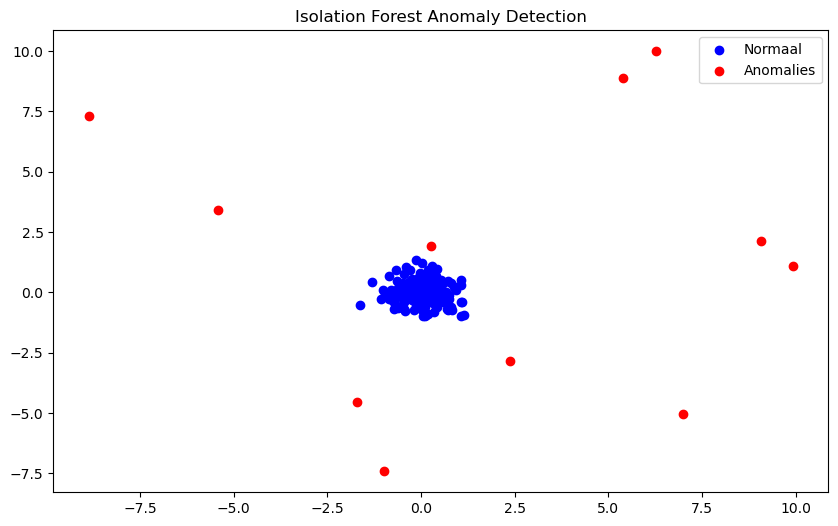

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest

# Kunstmatig voorbeeld
np.random.seed(42)
# normale punten
normal_data = 0.5 * np.random.randn(200, 2)
# Speciale punten, die liggen ver, die willen we kunnen detecteren
anomalous_data = 10 * np.random.uniform(low=-1, high=1, size=(10, 2))

# data samenvoegen
data = np.vstack([normal_data, anomalous_data])

# Isolation Forest model
clf = IsolationForest(contamination=0.05, random_state=42)
clf.fit(data)
y_pred = clf.predict(data)

# Plot
plt.figure(figsize=(10, 6))

# Kleurlabels
plt.scatter(data[y_pred == 1][:, 0], data[y_pred == 1][:, 1], c='b', label='Normaal')
plt.scatter(data[y_pred == -1][:, 0], data[y_pred == -1][:, 1], c='r', label='Anomalies')

plt.title('Isolation Forest Anomaly Detection')
plt.legend()
plt.show()

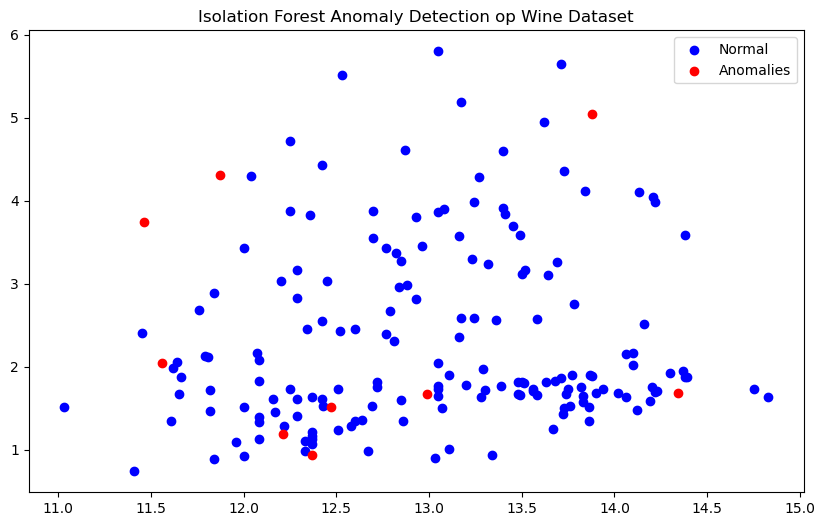

In [2]:
# nog een voorbeeldje, van de Wine set deze keer:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.ensemble import IsolationForest
from sklearn.model_selection import GridSearchCV

# Load the wine dataset
data = load_wine()
X = data.data  # Use the features from the dataset

# Split the data into a training set and a testing set
#X_train, X_test = train_test_split(X, test_size=0.2, random_state=42)

# Train the Isolation Forest model with the best hyperparameters on the training set
clf = IsolationForest(contamination=0.05, random_state=42)
clf.fit(X)
y_pred = clf.fit_predict(X)

# Plot 
plt.figure(figsize=(10, 6))
plt.scatter(X[y_pred == 1][:, 0], X[y_pred == 1][:, 1], c='b', label='Normal')
plt.scatter(X[y_pred == -1][:, 0], X[y_pred == -1][:, 1], c='r', label='Anomalies')

plt.title('Isolation Forest Anomaly Detection op Wine Dataset')
plt.legend()
plt.show()



Je zou kunnen proberen om hyperparameter tuning te doen op de contamination parameter, maar dat werkt niet zomaar. Dat komt omdat bij unsupervised algoritmes het niet mogelijk is om een score, een oordeel te vellen over de kwaliteit van dit algoritme. Maw, hyperparameter tuning bij unsupervised algoritmes is niet mogelijk! Dat is meteen ook het grootste nadeel: je moet op voorhand weten hoeveel % fouten je typisch mag verwachten in je dataset.

### Voordelen en nadelen van een Isolation Forest
**Voordelen**
- Efficiënt: dit algoritme is heel snel en kan grote datasets aan, want het is achterliggende gebaseerd op een random forest.
- Schaalbaar: ook meerdimensionale data is geen probleem
- Simpel om te gebruiken
- Geen voorwaarden over de verdeling van de data


**Nadelen**
- Hyperparameter tuning is nodig, namelijk de contamination parameter. Je moet dus op voorhand weten hoeveel anomalieën je typisch verwacht, anders gaat het fout
- Werkt goed voor geïsoleerde gevallen, niet  oor groepjes van data die zich vreemd gedragen
- Niet makkelijk te interpreteren waarom een item als anomalie is gelabeld
- Het is een unsupervised algoritme - dat kan een voordeel zijn, maar uiteraard ook een nadeel als je de labels toch zou hebben.

## Local Outlier Factor (LOF)

Deze methode kijkt naar de lokale dichtheid van punten. Punten die niet veel buren hebben, worden gemarkeerd en de punten met laagste dichtheid worden geklassificeerd als outliers. Op die manier werkt het algoritme lokaal: wanneer er een groepje punten apart staat, zal het algoritme dit groepje niet per se als anomalie beschouwen, als ze samen een dicht gebied vormen. Dit kan zowel een voor- als nadeel zijn, afhankelijk van de context van je dataset: als je weet dat er verschillende 'centers' zijn die dichtbevolkt zijn, dan zou dit goed moeten werken.

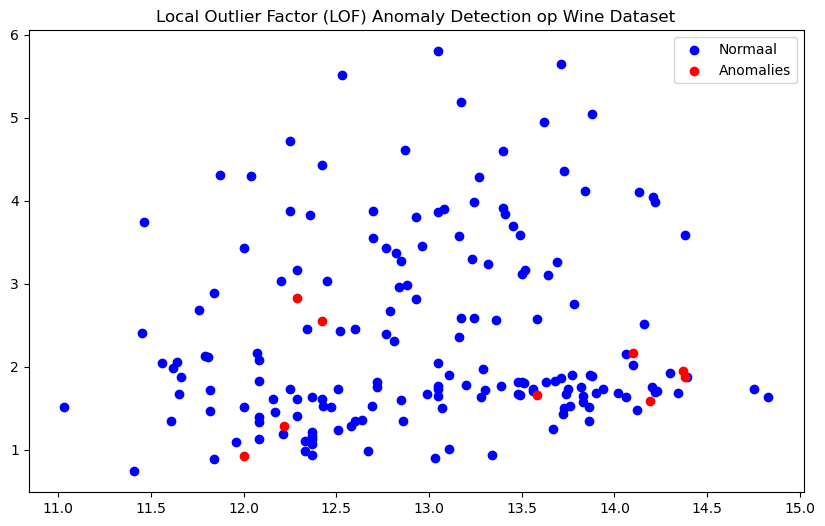

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.neighbors import LocalOutlierFactor

# Load the wine dataset
data = load_wine()
X = data.data  # Use the features from the dataset

# Local Outlier Factor (LOF) model
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.05)
y_pred = lof.fit_predict(X)

# Plot 
plt.figure(figsize=(10, 6))
plt.scatter(X[y_pred == 1][:, 0], X[y_pred == 1][:, 1], c='b', label='Normaal')
plt.scatter(X[y_pred == -1][:, 0], X[y_pred == -1][:, 1], c='r', label='Anomalies')

plt.title('Local Outlier Factor (LOF) Anomaly Detection op Wine Dataset')
plt.legend()
plt.show()

### Voordelen en nadelen van een Local Outlier Factor algoritme
**Voordelen**

- Unsupervised
- gevoelig voor lokale anomalieën
- Ongevoelig voor ruis in de dataset
- Schaalbaar
- Interpretabel: je kunt per punt de LOF score opvragen, en zelf kijken of het heel duidelijk of nipt is.

**Nadelen**
- Niet bruikbaar voor heel grote datasets, omdat het computattioneel duur is
- gevoelig voor hyperparameters, die je meestal moeilijk kunt inschatten (n_neigbors, contamination)
- in data met meer dan 1 zwaartepunt (multimodale data), is het niet zeker of het algoritme sommige modi niet zal labelen als anomalieën, als deze een lage dichtheid hebben.
- Geen globale context: het lokale karakter is meteen ook het grote nadeel van dit algoritme.


## Robust Covariance (EllipticEnvelope)

Dit algoritme berekent de robuste covariantie van de data. Dit gaat ruwweg als volgt:
1. Er wordt een schatting gemaakt van de *covariantie matrix*, deze matrix bevat voor elke combinnatie van features de correlatie-coëfficiënt tussen deze features. de traditionele, statistische manier om dit te berekenen met een testset, is heel gevoelig aan outliers. 
Er wordt dus een **robuuste schatting** gemaakt, die minder gevoelig is aan deze outliers. Hiervoor wordt het Minimum Covariance Determinant (MCD) algoritme gebruikt. Dit algoritme zoekt eerst actief naar een subset van punten in de dataset die minimaal worden beïnvloed doot outliers. Deze schatting van de covariantie matrix is dus niet exact, maar wel 'steviger', of dus robuuster in het vakjargon.
2. Op basis van deze matrix, zoekt het algoritme naar de **Mahalanobis afstand** van elk datapunt. Deze afstand drukt uit hoeveel standaarddeviaties een punt verwijderd is van haar gemiddelde, rekening houdend met meerdere dimensies:
   - Voor het gemiddelde van de dataset is deze Mahalanobis Distance exact 0
   - Indien je opschuift in de richting van een principale richting zoals berekend door PCA (Principal Component Analysis, zie de les over dimensie reductie), dan neemt de afstand toe
   - De Mahalanobis afstand is eigenlijk de gewone (Euclidische) afstand, maar dan in de ruimte die door PCA is getransformeerd.
   - De afstand is genoemd naar P.C. Mahalanobis in 1936, die een maat nodig had om in onderzoek de gelijkenissen van schedels te onderzoeken.
3. Er wordt een bepaalde afstand of **treshold** bepaald: punten die verder liggen worden als outliers geclassificeerd, punten gelijk of dichter als normaal.

De reden dat dit ook wel elliptic-envelope wordt genoemd, is omdat je dit kan voorstellen alsof er ellipsvormige schillen rond het centrum zijn van punten op gelijke afstand (als je analogie zoekt, denk wat aan de schillen van elektronen bij atomen in chemie, maar dus niet per se bolvormig)

**Belangrijke praktisch gevolg**:
Dit werkt dus goed voor datasets die van nature gecentreerd zijn rond 1 punt, zoals multivariate normale verdelingen. Dit is het belangrijkste dat je moet weten.

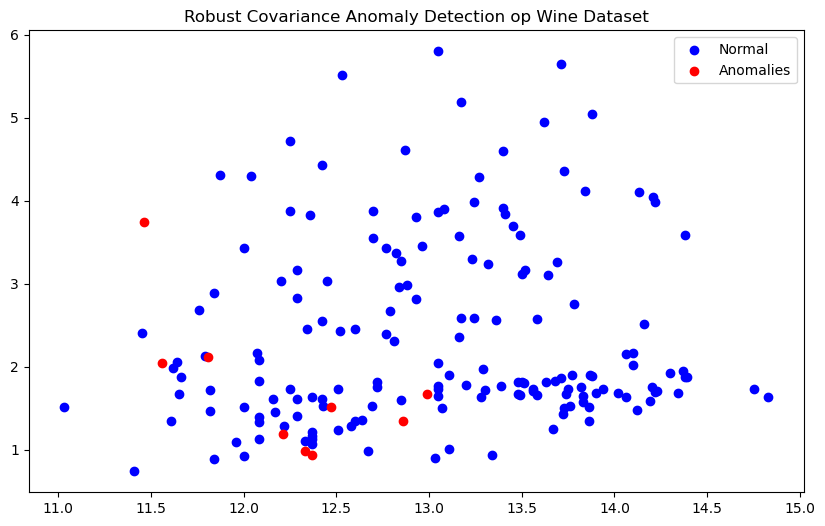

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.covariance import EllipticEnvelope

# inladen
data = load_wine()
X = data.data  

# Robust Covariance model (EllipticEnvelope)
robust_cov = EllipticEnvelope(contamination=0.05)
robust_cov.fit(X)

# Predict anomalies
y_pred = robust_cov.predict(X)

# Plot 
plt.figure(figsize=(10, 6))
plt.scatter(X[y_pred == 1][:, 0], X[y_pred == 1][:, 1], c='b', label='Normal')
plt.scatter(X[y_pred == -1][:, 0], X[y_pred == -1][:, 1], c='r', label='Anomalies')

plt.title('Robust Covariance Anomaly Detection op Wine Dataset')
plt.legend()
plt.show()


Met de volgende code gaan we eens kijken naar hoe die afstand precies werkt:

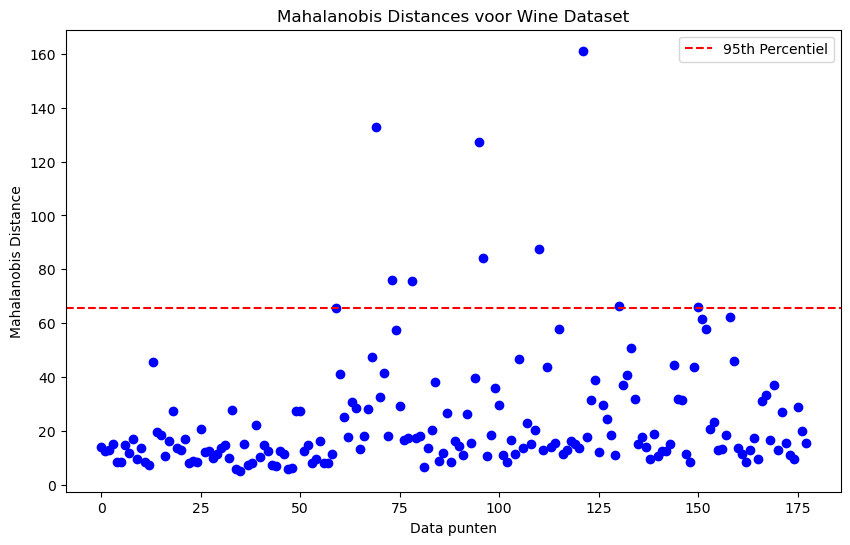

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.covariance import EllipticEnvelope

# Load the wine dataset
data = load_wine()
X = data.data  # Use the features from the dataset

# EllipticEnvelope model
robust_cov = EllipticEnvelope(contamination=0.05)
robust_cov.fit(X)

mahalanobis_distances = robust_cov.mahalanobis(X)

# Plot Mahalanobis distances
plt.figure(figsize=(10, 6))
plt.scatter(range(len(X)), mahalanobis_distances, c='b')
plt.axhline(np.percentile(mahalanobis_distances, 95), color='r', linestyle='--', label='95th Percentiel')
plt.xlabel('Data punten')
plt.ylabel('Mahalanobis Distance')
plt.title('Mahalanobis Distances voor Wine Dataset')
plt.legend()
plt.show()

In [6]:
np.percentile(mahalanobis_distances, 95)

65.64880113144761

### Visuele interpretatie

De volgende code geeft een visuelere interpretatie in een lager-dimensionale dataset (2). De code is zeker niet zelf te reproduceren, het zijn vooral de afbeeldingen ter illustratie die interessant kunnen zijn.

In [7]:
import numpy as np

# for consistent results
np.random.seed(7)

n_samples = 125
n_outliers = 25
n_features = 2

# generate Gaussisch data van shape (125, 2)
gen_cov = np.eye(n_features)
gen_cov[0, 0] = 2.0
X = np.dot(np.random.randn(n_samples, n_features), gen_cov)
# Manueel outliers toevoegen
outliers_cov = np.eye(n_features)
outliers_cov[np.arange(1, n_features), np.arange(1, n_features)] = 7.0
X[-n_outliers:] = np.dot(np.random.randn(n_outliers, n_features), outliers_cov)


In [8]:
import matplotlib.pyplot as plt
from sklearn.covariance import EmpiricalCovariance, MinCovDet

# fit een MCD robust estimator 
robust_cov = MinCovDet().fit(X)
print(
    "Estimated covariance matrix:\nMCD (Robust):\n{}".format(
        robust_cov.covariance_#, emp_cov.covariance_
    )
)

Estimated covariance matrix:
MCD (Robust):
[[ 3.26253567e+00 -3.06695631e-03]
 [-3.06695631e-03  1.22747343e+00]]


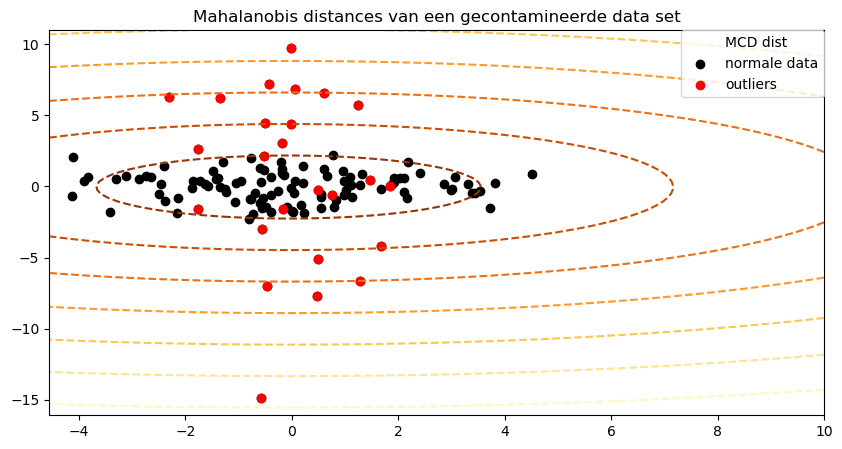

In [9]:
fig, ax = plt.subplots(figsize=(10, 5))
# Plot data set
inlier_plot = ax.scatter(X[:, 0], X[:, 1], color="black", label="normaal")
outlier_plot = ax.scatter(
    X[:, 0][-n_outliers:], X[:, 1][-n_outliers:], color="red", label="outliers"
)
ax.set_xlim(ax.get_xlim()[0], 10.0)
ax.set_title("Mahalanobis distances van een gecontamineerde data set")

# Create meshgrid of feature 1 and feature 2 values
xx, yy = np.meshgrid(
    np.linspace(plt.xlim()[0], plt.xlim()[1], 100),
    np.linspace(plt.ylim()[0], plt.ylim()[1], 100),
)
zz = np.c_[xx.ravel(), yy.ravel()]

# MCD Mahalanobis afstanden
mahal_robust_cov = robust_cov.mahalanobis(zz)
mahal_robust_cov = mahal_robust_cov.reshape(xx.shape)
robust_contour = ax.contour(
    xx, yy, np.sqrt(mahal_robust_cov), cmap=plt.cm.YlOrBr_r, linestyles="dashed"
)

# legend
ax.legend(
    [
        robust_contour.collections[1],
        inlier_plot,
        outlier_plot,
    ],
    ["MCD dist", "normale data", "outliers"],
    loc="upper right",
    borderaxespad=0,
)

plt.show()


### Voordelen en nadelen van een Robust Covariance algoritme
**Voordelen**

- Robuust voor outliers: zoals de naam het zegt, zal dit systeem ook goed werken voor zeer gecontamineerde datasets
- Unsupervised
- Visuale interpretatie mogelijk
- Tamelijk goed schaalbaar

**Nadelen**
- werkt enkel goed als onderliggende data Gaussisch (normaal) is verdeeld
    - *Dit is een belangrijke, beperkende voorwaarde*
- De contaminatie parameter moet zoals bij voorgaand ongeveer zijn gekend

### Normaliteit van data testen

Zie verder in deze notebook, dit kan je doen met statistische tests.

## Supervised
In wat volgt gaan we ervanuit dat we een dataset hebben met gelabelde outliers.

## One-class SVM
Deze techniek is gebaseerd op een support vector machine, wat we behandeld hebben tijdens de lessen over classificatie. We gaan eigenlijk gewoon een decision boundary maken tussen normale data en outliers, en gebruiken meestal een RBF-kernel op de SVM classifier. Ook hier geven we aan wat het verwachte percentage contamination is, maar hier noemen we die parameter *nu*.

Aangezien de dataset nu wel is gelabeld, is het wel mogelijk om aan Grid search te doen over deze parameter $nu$: we gaan een paar items toevoegen aan de Wine dataset en deze expliciet labelen als outliers, en dan trainen:

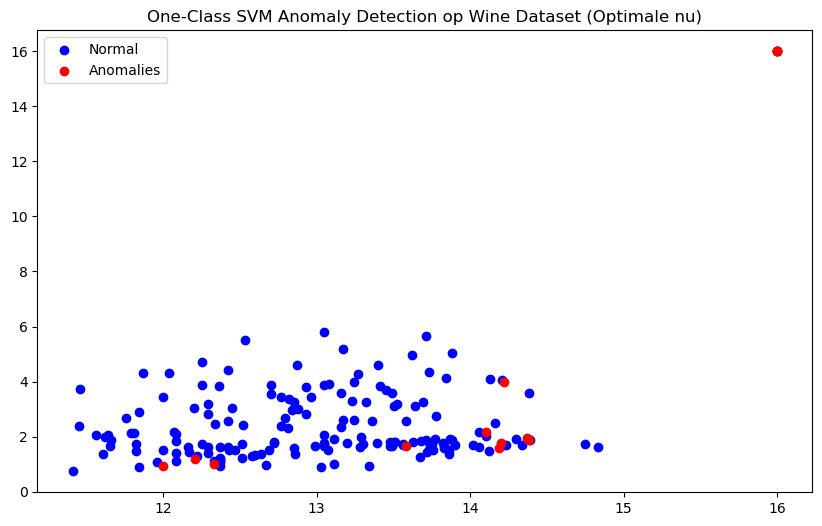

Optimale nu: 0.09


In [11]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.svm import OneClassSVM
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer, f1_score

# inladen
data = load_wine()
X = data.data

# Kunstmatige extra outliers
num_anomalies = 5
anomalous_indices = np.random.choice(range(len(X)), num_anomalies, replace=False)
X[anomalous_indices, :] = 16  # outlier

#  labels: 1 voor normal data, -1 voor outliers
y = np.ones(len(X))
y[anomalous_indices] = -1

# hyperparameter tuning
nu_values = np.linspace(0.01, 0.5, 20)
param_grid = {'nu': nu_values}

# One-Class SVM model
svm = OneClassSVM(kernel='rbf')

# GridSearchCV: we moeten zelf aangeven hoe we gaan meten; Hier kiezen we de F1 score
scorer = make_scorer(f1_score, pos_label=-1)
# hyperparameter tuning
grid_search = GridSearchCV(svm, param_grid, cv=5, scoring=scorer)
grid_search.fit(X, y)

# Bests hyperparameter
best_nu = grid_search.best_params_['nu']

# One-Class SVM model met beste nu
best_svm = OneClassSVM(nu=best_nu, kernel='rbf')
best_svm.fit(X)
y_pred = best_svm.predict(X)

# Plot 
plt.figure(figsize=(10, 6))
plt.scatter(X[y_pred == 1][:, 0], X[y_pred == 1][:, 1], c='b', label='Normal')
plt.scatter(X[y_pred == -1][:, 0], X[y_pred == -1][:, 1], c='r', label='Anomalies')

plt.title('One-Class SVM Anomaly Detection op Wine Dataset (Optimale nu)')
plt.legend()
plt.show()

print(f"Optimale nu: {best_nu:.2f}")


## Statistische tests: voorbeelden

**Shapiro Wilkinson**

$H_0$: data is normaal

In [12]:
import numpy as np
from scipy.stats import shapiro

# Voorbeelddata
np.random.seed(42)
sample_data = np.random.normal(loc=0, scale=1, size=100)

#Shapiro-Wilk test
statistic, p_value = shapiro(sample_data)

print("Shapiro-Wilk Statistic:", statistic)
print("P-value:", p_value)

# Interpretatie
alpha = 0.05  # Significance level
if p_value > alpha:
    print("Data lijkt normaal (accepteer H0)")
else:
    print("Data lijkt niet normaal (verwerp/reject H0)")


Shapiro-Wilk Statistic: 0.9898831844329834
P-value: 0.6551515460014343
Data lijkt normaal (accepteer H0)


**Anderson-Darling**

$H_0$: data komt uit een (multi-)normale verdeling

Bij een Anderson-Darling kun je ook nog algemener testen of data uit een ander soort verdeling komt. Daarvoor kan je de `` parameter aanpassen in de test.

In [13]:
import numpy as np
from scipy.stats import anderson

# 2D data
np.random.seed(42)
sample_data_2d = np.random.multivariate_normal(mean=[0, 0], cov=[[1, 0.5], [0.5, 1]], size=100)

# Anderson-Darling 
result = anderson(sample_data_2d.flatten())

print("Anderson-Darling Statistic:", result.statistic)
print("Critical Values:", result.critical_values)
print("Significance Levels:", result.significance_level)

# Interpretatie
print("\nNormality Test Result:")
for i in range(len(result.critical_values)):
    if result.statistic < result.critical_values[i]:
        print(f"Op {result.significance_level[i]}% significantie level, data is normaal (accepteer H0)")
    else:
        print(f"Op {result.significance_level[i]}% significantie level, data lijkt NIET normaal (verwerp H0)")


Anderson-Darling Statistic: 0.5103057664426842
Critical Values: [0.565 0.644 0.772 0.901 1.071]
Significance Levels: [15.  10.   5.   2.5  1. ]

Normality Test Result:
Op 15.0% significantie level, data is normaal (accepteer H0)
Op 10.0% significantie level, data is normaal (accepteer H0)
Op 5.0% significantie level, data is normaal (accepteer H0)
Op 2.5% significantie level, data is normaal (accepteer H0)
Op 1.0% significantie level, data is normaal (accepteer H0)


**2 sample Kolmogorov-Smirnov**

$H_0$: 2 steekproeven komen uit dezelfde verdeling

In [14]:
import numpy as np
from scipy.stats import ks_2samp

# Voorbeelddata
np.random.seed(42)
sample1 = np.random.normal(loc=0, scale=1, size=100)
sample2 = np.random.normal(loc=0.01, scale=1, size=120)

# Kolmogorov-Smirnov test
statistic, p_value = ks_2samp(sample1, sample2)

print("Kolmogorov-Smirnov Statistic:", statistic)
print("P-value:", p_value)

# Interpretatie
alpha = 0.05  # Significance level
if p_value > alpha:
    print("Uit dezelfde verdeling (accepteer H0)")
else:
    print("Uit verschillende distributies (verwerp H0)")


Kolmogorov-Smirnov Statistic: 0.12833333333333333
P-value: 0.30297024961163926
Uit dezelfde verdeling (accepteer H0)
